**Setup**

In [5]:
!pip install qiskit==1.1.1 qiskit-machine-learning==0.8.2 qiskit-aer==0.14.2 qiskit-algorithms==0.3.0


[notice] A new release of pip is available: 23.2.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import os
import sys
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import KNNImputer
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import (
    train_test_split, GridSearchCV, StratifiedKFold
)
from sklearn.feature_selection import RFE, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier,
    GradientBoostingClassifier, AdaBoostClassifier,
    VotingClassifier, StackingClassifier
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    matthews_corrcoef, ConfusionMatrixDisplay,
    roc_curve, auc as sk_auc
)
from sklearn.decomposition import PCA
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from xgboost import XGBClassifier
from matplotlib.patches import Patch
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size']  = 11
RANDOM_STATE = 20

os.makedirs('../outputs/plots',   exist_ok=True)
os.makedirs('../outputs/models',  exist_ok=True)
os.makedirs('../outputs/metrics', exist_ok=True)

In [7]:
FEATURE_COLS = [
    'Pregnancies', 'Glucose', 'BloodPressure',
    'SkinThickness', 'Insulin', 'BMI',
    'DiabetesPedigreeFunction', 'Age'
]
TARGET_COL = 'Outcome'
FEATURE_UNITS = {
    'Pregnancies':              'count',
    'Glucose':                  'mg/dL',
    'BloodPressure':            'mm Hg',
    'SkinThickness':            'mm',
    'Insulin':                  'μU/mL',
    'BMI':                      'kg/m²',
    'DiabetesPedigreeFunction': 'score',
    'Age':                      'years'
}
ZERO_INVALID_COLS = {
    'Glucose':       1,
    'BloodPressure': 1,
    'SkinThickness': 1,
    'Insulin':       1,
    'BMI':           1,
}

**Load Dataset**

In [8]:
df = pd.read_csv("../data/diabetes.csv")
print("=" * 55)
print("  PIMA Indian Diabetes Dataset — Overview")
print("=" * 55)
print(f"  Shape          : {df.shape[0]} rows × {df.shape[1]} columns")
print(f"  Diabetic (1)   : {df['Outcome'].sum()} ({df['Outcome'].mean()*100:.1f}%)")
print(f"  Non-diabetic(0): {(df['Outcome']==0).sum()} ({(df['Outcome']==0).mean()*100:.1f}%)")
print("=" * 55)
print(df.describe().round(2))

  PIMA Indian Diabetes Dataset — Overview
  Shape          : 768 rows × 9 columns
  Diabetic (1)   : 268 (34.9%)
  Non-diabetic(0): 500 (65.1%)
       Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin     BMI  \
count       768.00   768.00         768.00         768.00   768.00  768.00   
mean          3.85   120.89          69.11          20.54    79.80   31.99   
std           3.37    31.97          19.36          15.95   115.24    7.88   
min           0.00     0.00           0.00           0.00     0.00    0.00   
25%           1.00    99.00          62.00           0.00     0.00   27.30   
50%           3.00   117.00          72.00          23.00    30.50   32.00   
75%           6.00   140.25          80.00          32.00   127.25   36.60   
max          17.00   199.00         122.00          99.00   846.00   67.10   

       DiabetesPedigreeFunction     Age  Outcome  
count                    768.00  768.00   768.00  
mean                       0.47   33.24     0.35  


**EDA**

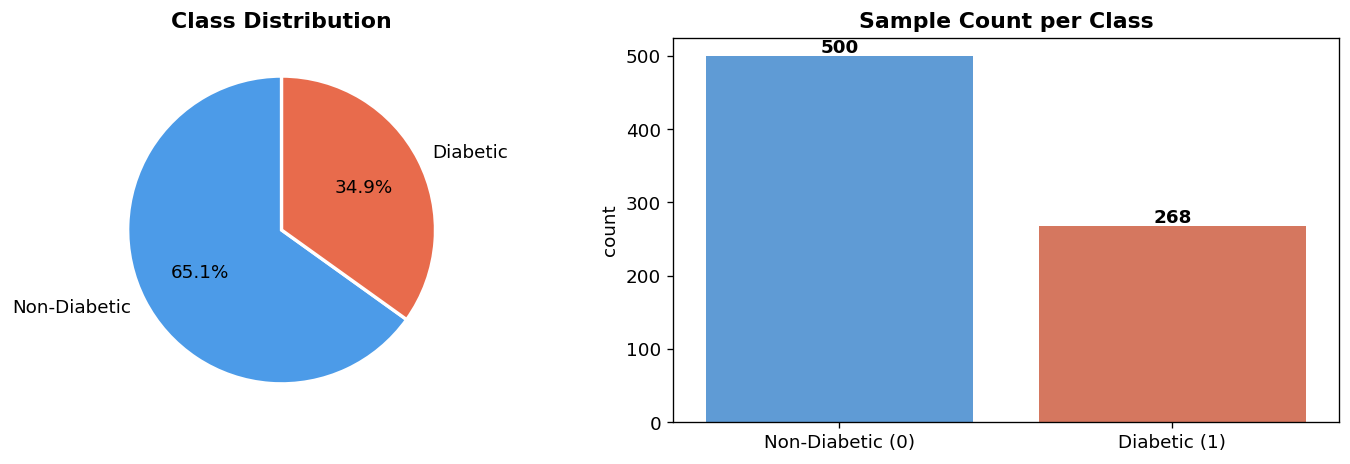

In [9]:
counts = df[TARGET_COL].value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].pie(
    counts,
    labels=['Non-Diabetic', 'Diabetic'],
    autopct='%1.1f%%',
    colors=['#4C9BE8', '#E86B4C'],
    startangle=90,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)
axes[0].set_title('Class Distribution', fontweight='bold')
sns.countplot(
    data=df,
    x=TARGET_COL,
    ax=axes[1],
    palette=['#4C9BE8', '#E86B4C']
)
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Non-Diabetic (0)', 'Diabetic (1)'])
axes[1].set_title('Sample Count per Class', fontweight='bold')
axes[1].set_xlabel('')
for bar in axes[1].patches:
    axes[1].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 5,
        f'{int(bar.get_height())}',
        ha='center',
        fontweight='bold'
    )
plt.tight_layout()
plt.savefig('../outputs/plots/01_class_distribution.png', bbox_inches='tight')
plt.show()

In [10]:
zero_counts = {}
print(f"\n  {'Feature':<28} {'Zeros':>6}  {'%':>6}")
print("-" * 50)
for col in FEATURE_COLS:
    n = (df[col] == 0).sum()
    zero_counts[col] = n
    tag = '  ← MISSING' if col in ZERO_INVALID_COLS else ''
    print(f"  {col:<28} {n:>6}  {n/len(df)*100:>5.1f}%{tag}")
total_missing = sum(zero_counts[c] for c in ZERO_INVALID_COLS)
print(f"\n  Total cells to impute: {total_missing}")
print(df[TARGET_COL].unique())
print(df[TARGET_COL].dtype)



  Feature                       Zeros       %
--------------------------------------------------
  Pregnancies                     111   14.5%
  Glucose                           5    0.7%  ← MISSING
  BloodPressure                    35    4.6%  ← MISSING
  SkinThickness                   227   29.6%  ← MISSING
  Insulin                         374   48.7%  ← MISSING
  BMI                              11    1.4%  ← MISSING
  DiabetesPedigreeFunction          0    0.0%
  Age                               0    0.0%

  Total cells to impute: 652
[1 0]
int64


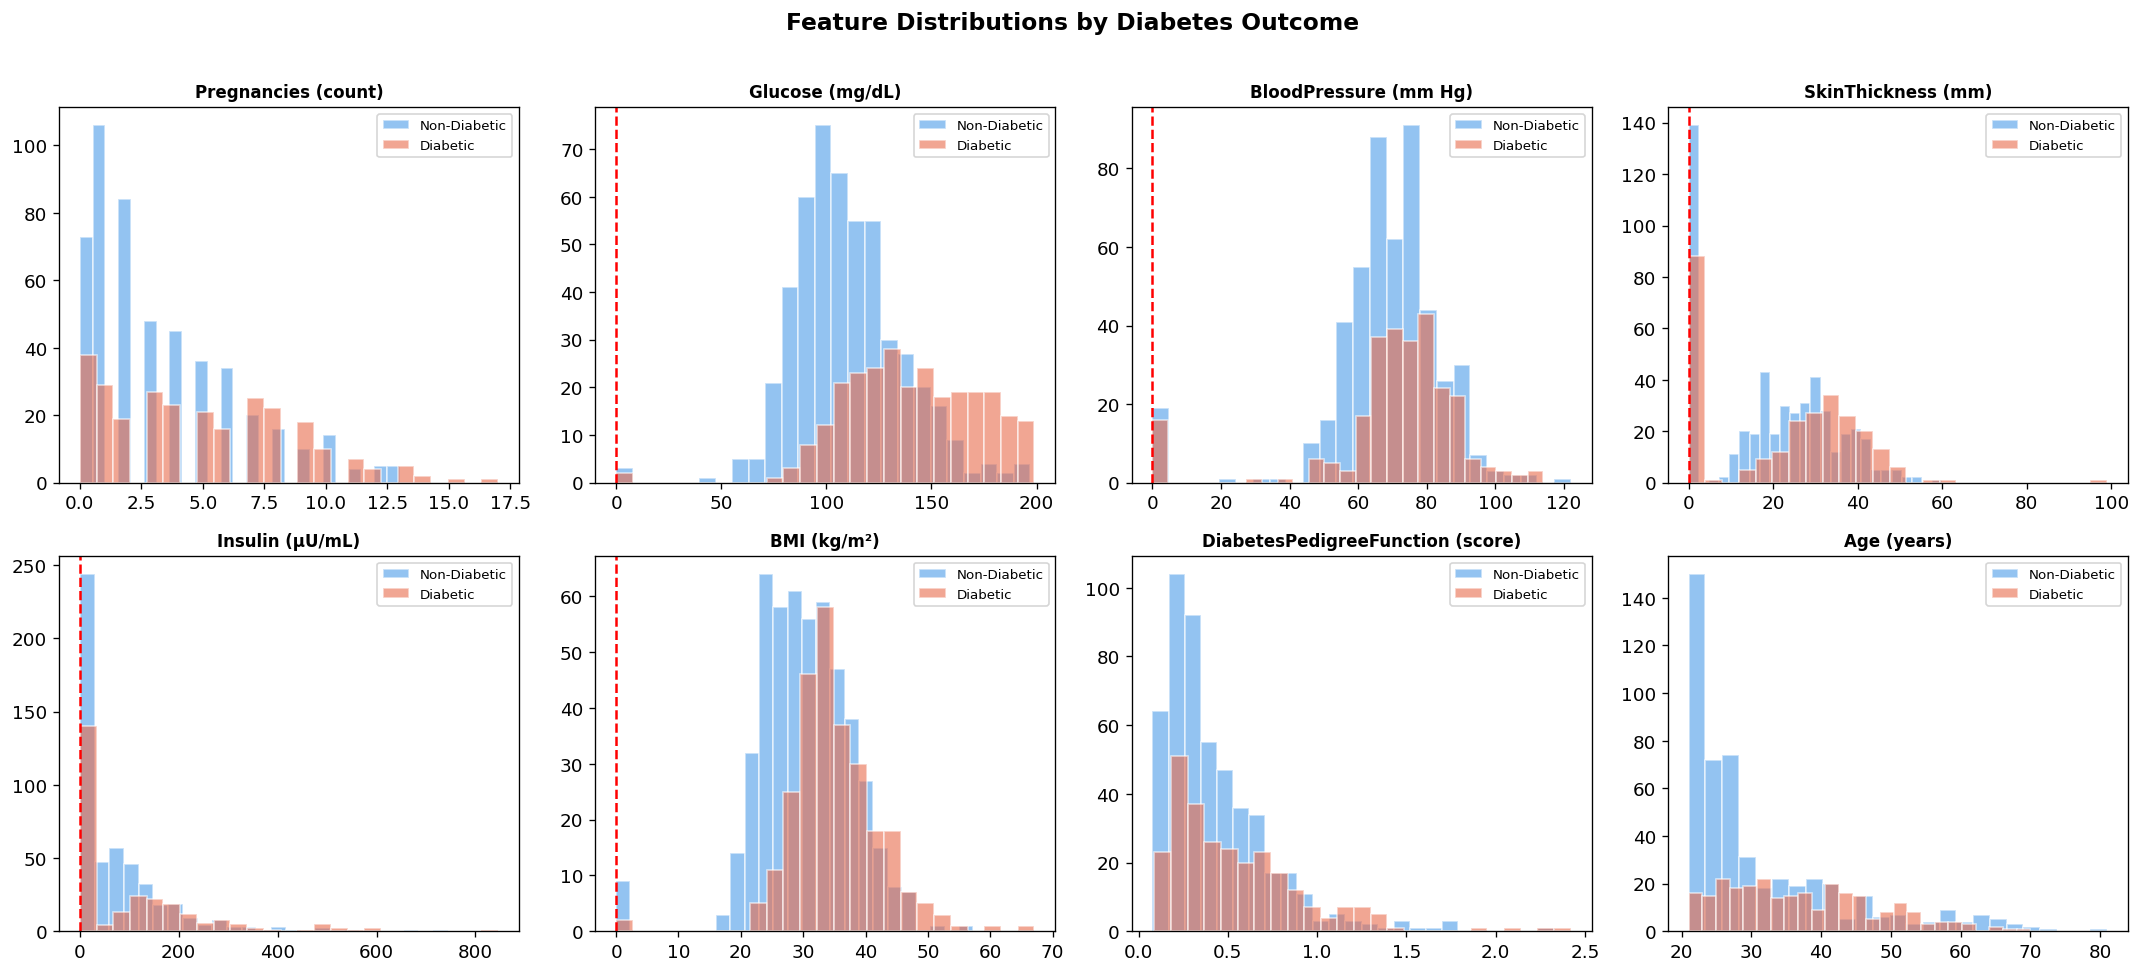

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, col in enumerate(FEATURE_COLS):
    for outcome, color, label in [(0, '#4C9BE8', 'Non-Diabetic'), (1, '#E86B4C', 'Diabetic')]:
        axes[i].hist(df[df[TARGET_COL]==outcome][col], bins=25, alpha=0.6,
                     color=color, label=label, edgecolor='white')
    axes[i].set_title(f'{col} ({FEATURE_UNITS[col]})', fontweight='bold', fontsize=10)
    axes[i].legend(fontsize=8)
    if col in ZERO_INVALID_COLS and zero_counts[col] > 0:
        axes[i].axvline(0, color='red', linestyle='--', linewidth=1.5)
plt.suptitle('Feature Distributions by Diabetes Outcome', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('../outputs/plots/02_feature_distributions.png', bbox_inches='tight')
plt.show()

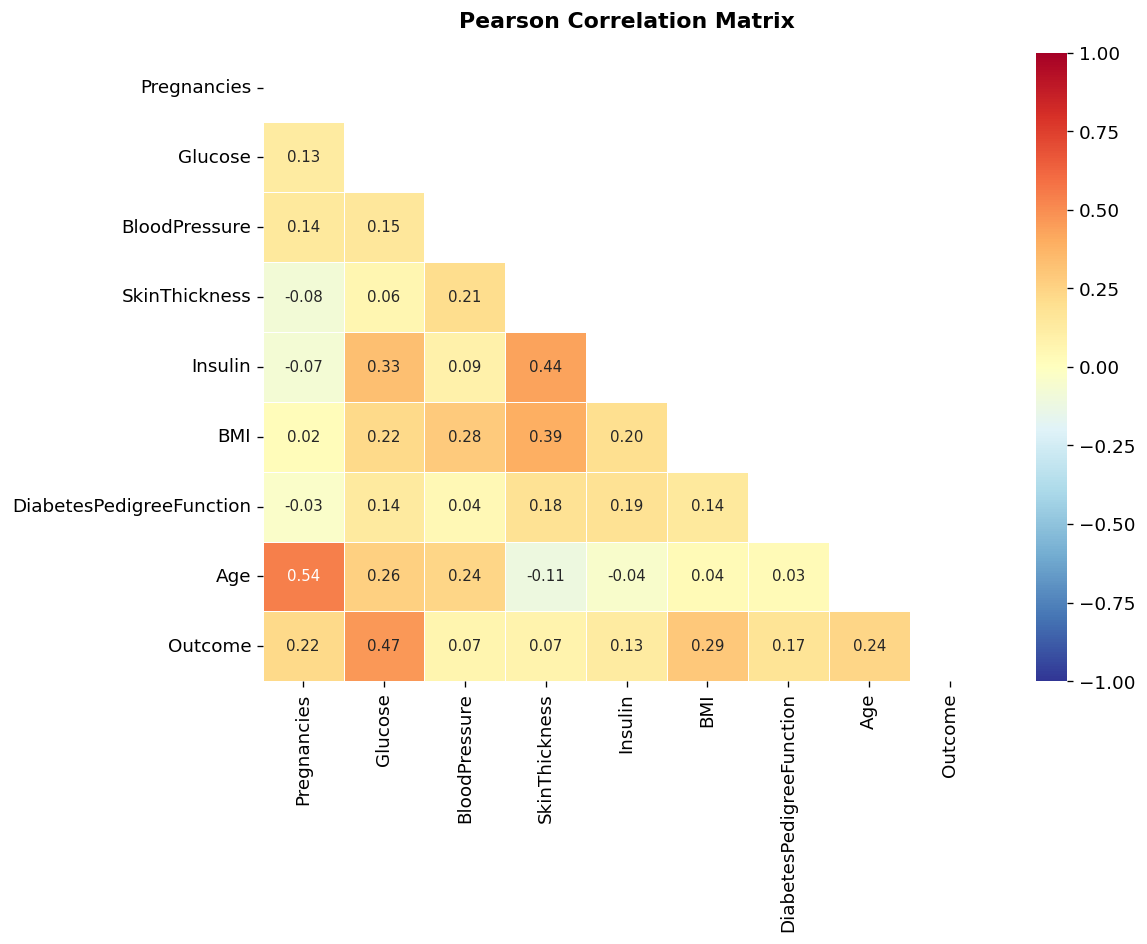

Feature correlations with Outcome:
  Glucose                      +0.467  █████████
  BMI                          +0.293  █████
  Age                          +0.238  ████
  Pregnancies                  +0.222  ████
  DiabetesPedigreeFunction     +0.174  ███
  Insulin                      +0.131  ██
  SkinThickness                +0.075  █
  BloodPressure                +0.065  █


In [12]:
fig, ax = plt.subplots(figsize=(10, 8))
corr = df.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdYlBu_r',
            center=0, vmin=-1, vmax=1, linewidths=0.5, ax=ax, annot_kws={'size': 9})
ax.set_title('Pearson Correlation Matrix', fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('../outputs/plots/03_correlation_heatmap.png', bbox_inches='tight')
plt.show()
outcome_corr = corr['Outcome'].drop('Outcome').sort_values(ascending=False)
print("Feature correlations with Outcome:")
for feat, val in outcome_corr.items():
    print(f"  {feat:<28} {'+' if val>0 else ''}{val:.3f}  {'█'*int(abs(val)*20)}")

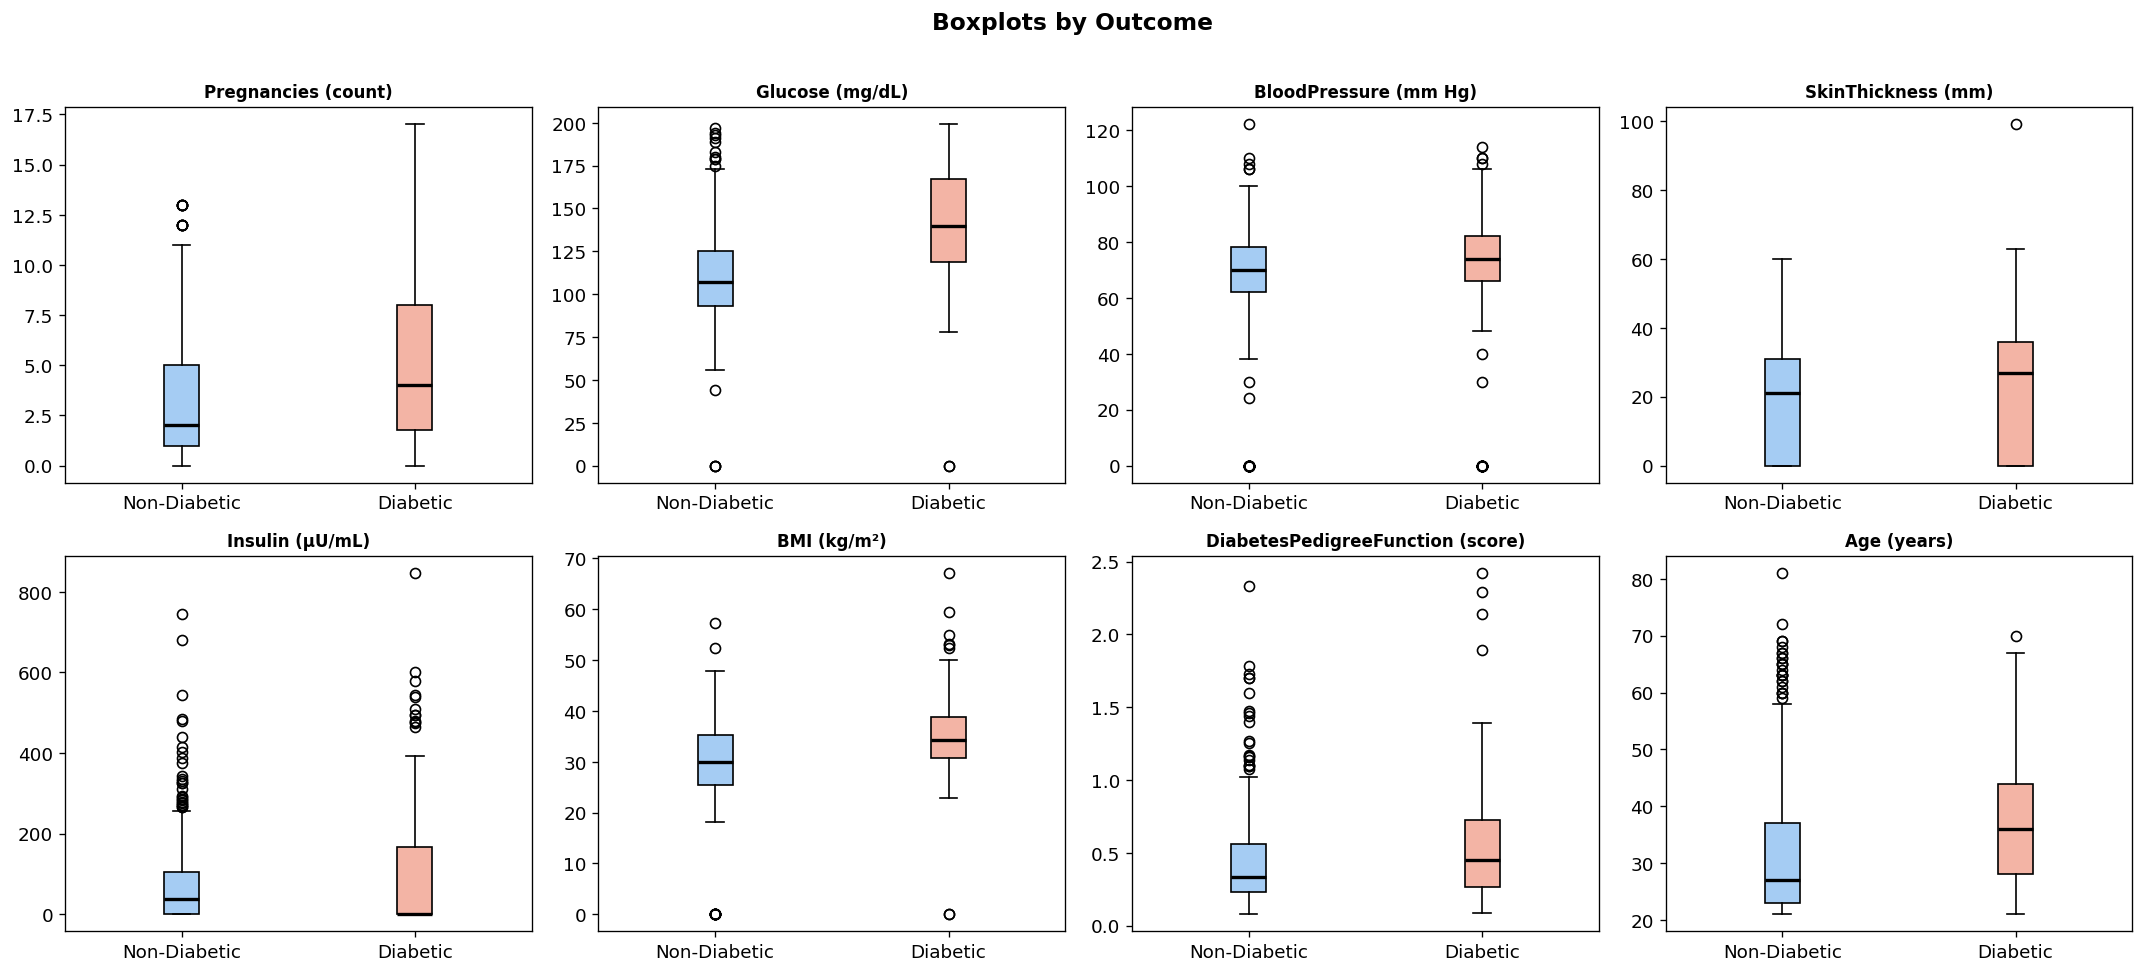

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, col in enumerate(FEATURE_COLS):
    bp = axes[i].boxplot(
        [df[df[TARGET_COL]==0][col].values, df[df[TARGET_COL]==1][col].values],
        labels=['Non-Diabetic', 'Diabetic'], patch_artist=True,
        medianprops=dict(color='black', linewidth=2)
    )
    bp['boxes'][0].set_facecolor('#4C9BE880')
    bp['boxes'][1].set_facecolor('#E86B4C80')
    axes[i].set_title(f'{col} ({FEATURE_UNITS[col]})', fontweight='bold', fontsize=10)
plt.suptitle('Boxplots by Outcome', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('../outputs/plots/04_boxplots.png', bbox_inches='tight')
plt.show()

**Train/Test Split**

In [14]:
X_raw = df[FEATURE_COLS].values
y     = df[TARGET_COL].values

X_train_raw, X_test_raw, y_train_raw, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f"Train: {X_train_raw.shape[0]}  Test: {X_test_raw.shape[0]}")


Train: 614  Test: 154


**Replace Zeros With Nan** (common for ml and qml)

In [15]:
ZERO_INVALID_LIST = list(ZERO_INVALID_COLS.keys())
ZERO_INVALID_IDX  = [FEATURE_COLS.index(c) for c in ZERO_INVALID_LIST]

X_train_nan = X_train_raw.astype(float).copy()
X_test_nan  = X_test_raw.astype(float).copy()

for idx in ZERO_INVALID_IDX:
    before_train = (X_train_nan[:, idx] == 0).sum()
    before_test  = (X_test_nan[:,  idx] == 0).sum()
    X_train_nan[:, idx] = np.where(X_train_nan[:, idx] == 0, np.nan, X_train_nan[:, idx])
    X_test_nan[:,  idx] = np.where(X_test_nan[:,  idx] == 0, np.nan, X_test_nan[:,  idx])
    print(f"  {FEATURE_COLS[idx]:<28} train: {before_train} zeros → NaN  |  test: {before_test} zeros → NaN")

print(f"\nTrain NaN cells: {np.isnan(X_train_nan).sum()}")
print(f"Test  NaN cells: {np.isnan(X_test_nan).sum()}")

  Glucose                      train: 3 zeros → NaN  |  test: 2 zeros → NaN
  BloodPressure                train: 27 zeros → NaN  |  test: 8 zeros → NaN
  SkinThickness                train: 177 zeros → NaN  |  test: 50 zeros → NaN
  Insulin                      train: 301 zeros → NaN  |  test: 73 zeros → NaN
  BMI                          train: 10 zeros → NaN  |  test: 1 zeros → NaN

Train NaN cells: 518
Test  NaN cells: 134


**Missingness Indicator Creation**(common for ml and qml)

In [16]:
train_indicators = (np.isnan(X_train_nan[:, ZERO_INVALID_IDX])).astype(float)
test_indicators  = (np.isnan(X_test_nan[:,  ZERO_INVALID_IDX])).astype(float)

indicator_names = [f'{c}_missing' for c in ZERO_INVALID_LIST]

print(f"Missingness indicators created: {indicator_names}")
print(f"  Train indicator shape: {train_indicators.shape}")
print(f"  Test  indicator shape: {test_indicators.shape}")

Missingness indicators created: ['Glucose_missing', 'BloodPressure_missing', 'SkinThickness_missing', 'Insulin_missing', 'BMI_missing']
  Train indicator shape: (614, 5)
  Test  indicator shape: (154, 5)


KNN Imputation for ML

In [17]:
print("Applying KNN Imputer for ML branch (k=5) — fit on train only...")

imputer_ml = KNNImputer(n_neighbors=5, weights='uniform')

X_train_ml_imputed = imputer_ml.fit_transform(X_train_nan)
X_test_ml_imputed  = imputer_ml.transform(X_test_nan)

print(f"ML Train NaN remaining: {np.isnan(X_train_ml_imputed).sum()}")
print(f"ML Test  NaN remaining: {np.isnan(X_test_ml_imputed).sum()}")

X_train_ml_imputed_full = np.hstack([X_train_ml_imputed, train_indicators])
X_test_ml_imputed_full  = np.hstack([X_test_ml_imputed,  test_indicators])

FEATURE_COLS_WITH_IND_ML = FEATURE_COLS + indicator_names

print(f"\nML feature matrix after imputation + indicators: {X_train_ml_imputed_full.shape[1]} columns")

Applying KNN Imputer for ML branch (k=5) — fit on train only...
ML Train NaN remaining: 0
ML Test  NaN remaining: 0

ML feature matrix after imputation + indicators: 13 columns


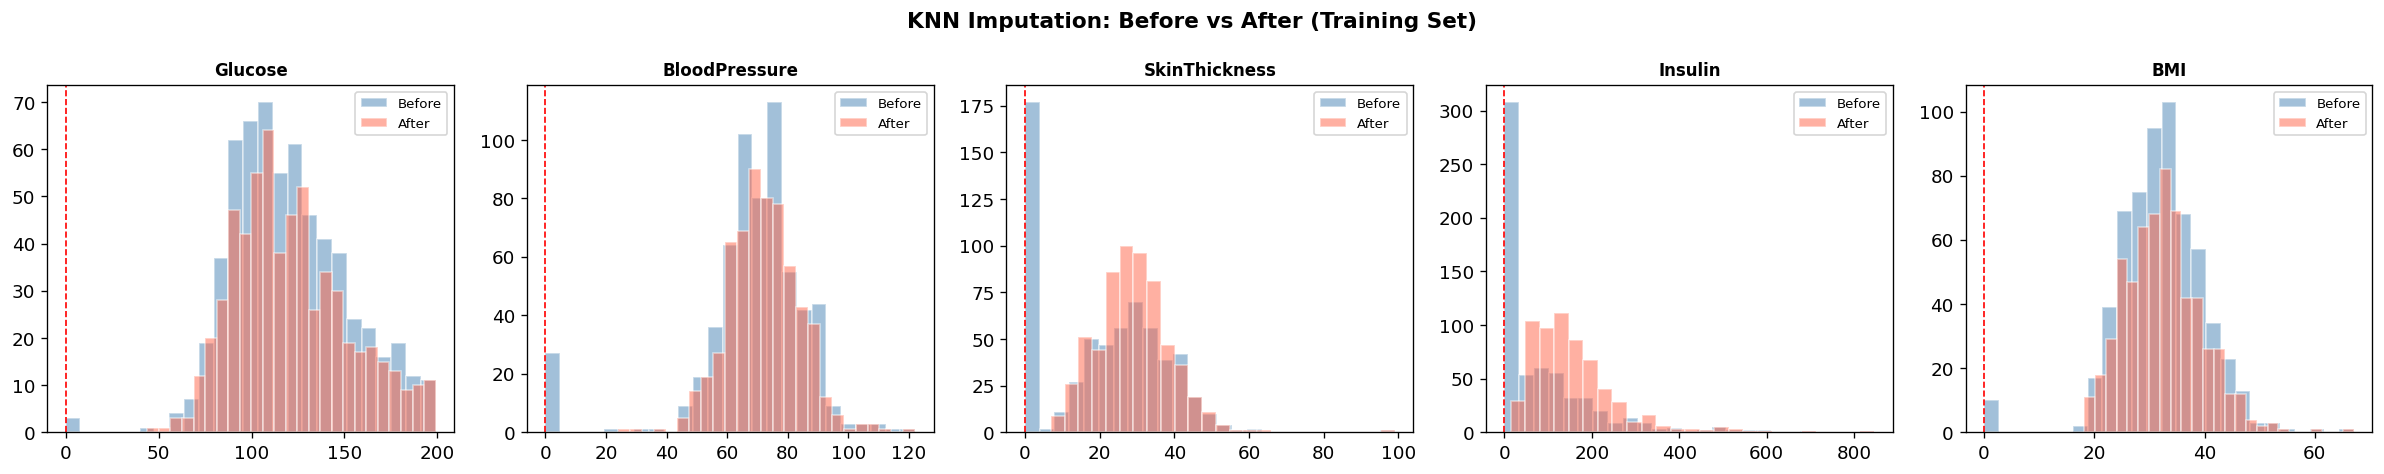

In [18]:
fig, axes = plt.subplots(1, len(ZERO_INVALID_COLS), figsize=(20, 4))
for i, col in enumerate(ZERO_INVALID_COLS):
    col_idx = FEATURE_COLS.index(col)
    axes[i].hist(X_train_raw[:, col_idx], bins=25, alpha=0.5, color='steelblue', label='Before', edgecolor='white')
    axes[i].hist(X_train_ml_imputed[:, col_idx], bins=25, alpha=0.5, color='tomato', label='After', edgecolor='white')
    axes[i].set_title(col, fontweight='bold', fontsize=10)
    axes[i].legend(fontsize=8)
    axes[i].axvline(0, color='red', linestyle='--', linewidth=1)
plt.suptitle('KNN Imputation: Before vs After (Training Set)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/plots/06_imputation.png', bbox_inches='tight')
plt.show()

In [19]:
joblib.dump(imputer_ml, '../outputs/models/knn_imputer_ml.pkl')

['../outputs/models/knn_imputer_ml.pkl']

**Classical ML Branch**

**ML Scaling**

In [20]:
scaler_ml_8feat = MinMaxScaler()

X_train_ml_scaled_8 = scaler_ml_8feat.fit_transform(X_train_ml_imputed)
X_test_ml_scaled_8 = scaler_ml_8feat.transform(X_test_ml_imputed)

print(f"8-feat scaling — train range: [{X_train_ml_scaled_8.min():.3f}, {X_train_ml_scaled_8.max():.3f}]")

joblib.dump(scaler_ml_8feat, '../outputs/models/minmax_scaler_8feat.pkl')

8-feat scaling — train range: [0.000, 1.000]


['../outputs/models/minmax_scaler_8feat.pkl']

**PCA Reduction for ML**

In [21]:
N_COMPONENTS_ML = 4
pca_ml = PCA(n_components=N_COMPONENTS_ML, random_state=RANDOM_STATE)
X_train_ml_pca = pca_ml.fit_transform(X_train_ml_scaled_8)
X_test_ml_pca  = pca_ml.transform(X_test_ml_scaled_8)

explained_ml  = pca_ml.explained_variance_ratio_
cumulative_ml = np.cumsum(explained_ml)
print(f" ML Variance retained ({N_COMPONENTS_ML} components): {cumulative_ml[-1]*100:.2f}%")
for i, (ev, cum) in enumerate(zip(explained_ml, cumulative_ml)):
    print(f"  PC{i+1}: {ev*100:.2f}%  cumulative: {cum*100:.2f}%")

 ML Variance retained (4 components): 79.80%
  PC1: 36.48%  cumulative: 36.48%
  PC2: 22.33%  cumulative: 58.82%
  PC3: 11.76%  cumulative: 70.58%
  PC4: 9.22%  cumulative: 79.80%


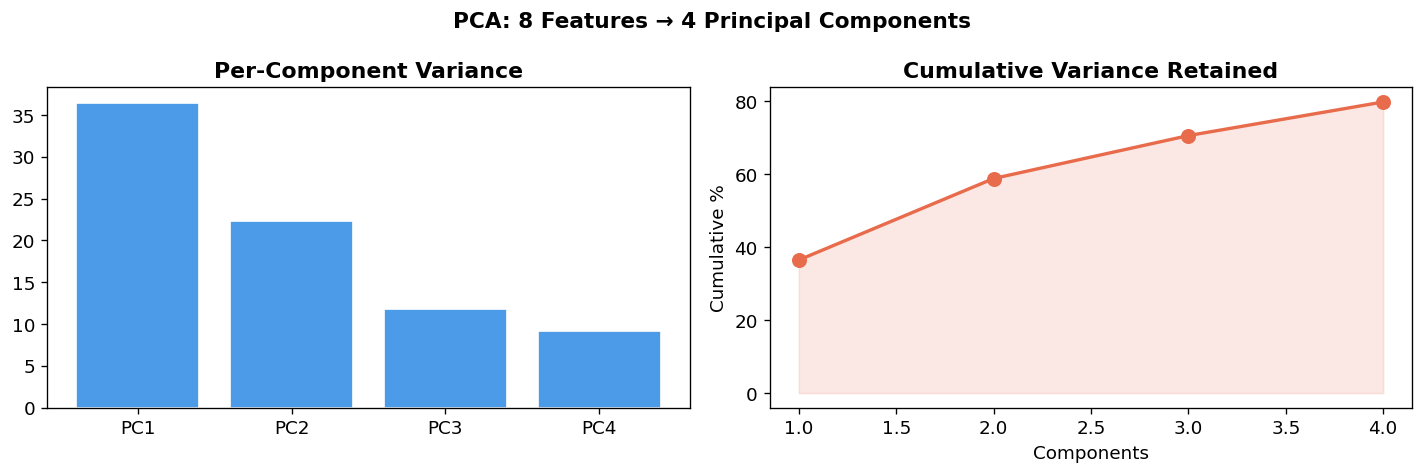

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar([f'PC{i+1}' for i in range(N_COMPONENTS_ML)], explained_ml*100, color='#4C9BE8', edgecolor='white')
axes[0].set_title('Per-Component Variance', fontweight='bold')
axes[1].plot(range(1, N_COMPONENTS_ML+1), cumulative_ml*100, 'o-', color='#E86B4C', linewidth=2, markersize=8)
axes[1].fill_between(range(1, N_COMPONENTS_ML+1), cumulative_ml*100, alpha=0.15, color='#E86B4C')
axes[1].set_title('Cumulative Variance Retained', fontweight='bold')
axes[1].set_xlabel('Components')
axes[1].set_ylabel('Cumulative %')
plt.suptitle(f'PCA: 8 Features → {N_COMPONENTS_ML} Principal Components', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/plots/13_pca_variance.png', bbox_inches='tight')
plt.show()

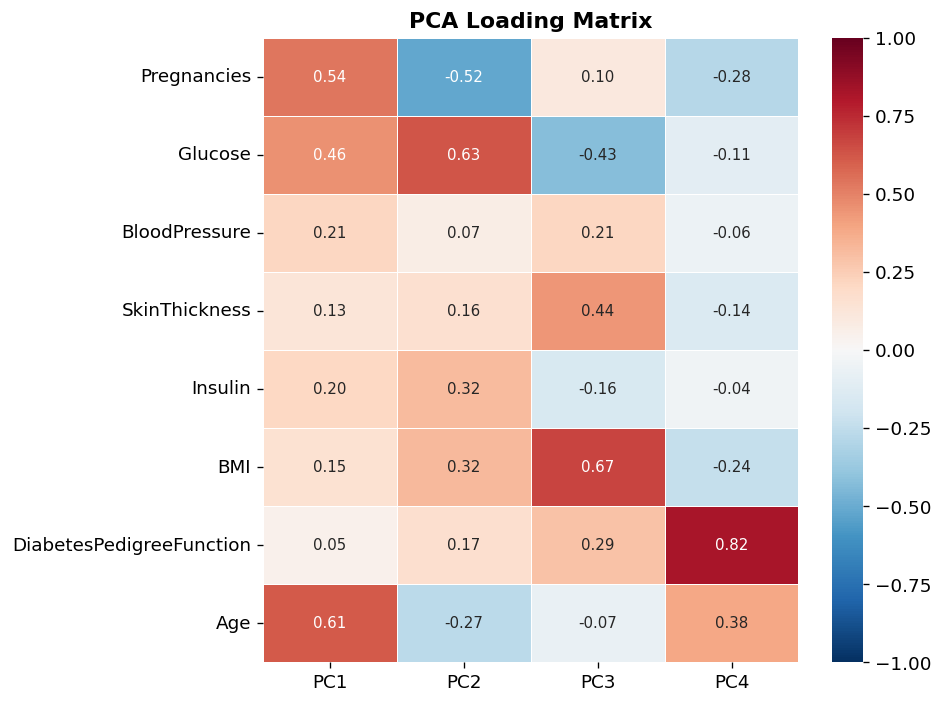

In [23]:
loadings = pd.DataFrame(pca_ml.components_.T, index=FEATURE_COLS,
                         columns=[f'PC{i+1}' for i in range(N_COMPONENTS_ML)])
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(loadings, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, linewidths=0.5, ax=ax, annot_kws={'size': 9})
ax.set_title('PCA Loading Matrix', fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/plots/14_pca_loadings.png', bbox_inches='tight')
plt.show()


**LDA Reduction for Classical ML**

LDA — 8 features → 1 discriminant component
  Explained variance ratio : [1.]
  Train : (614, 1)   Test : (154, 1)
  Train range : [-2.670, 4.438]


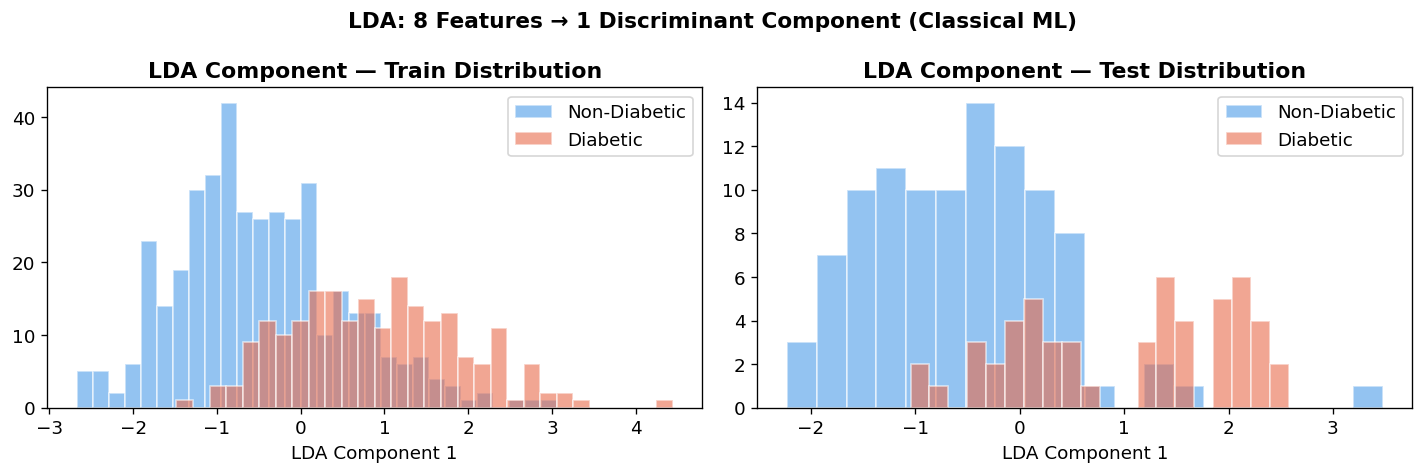

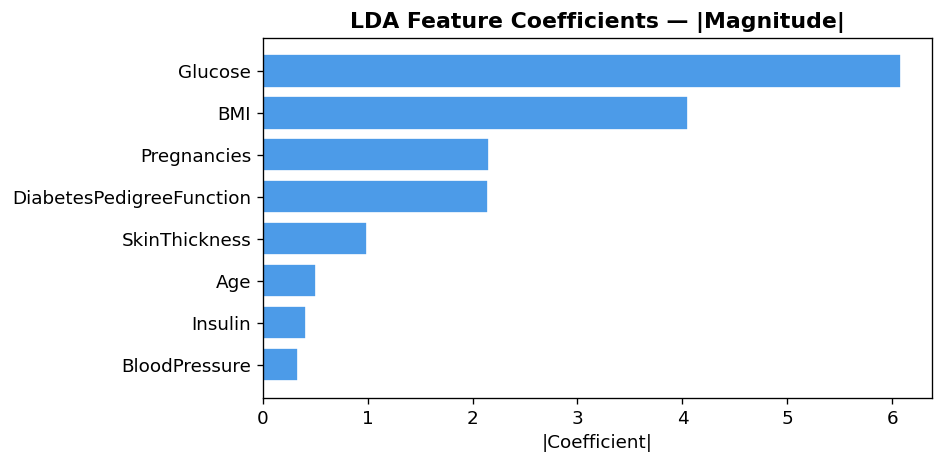

LDA saved → ../outputs/models/lda_ml.pkl


In [24]:
# LDA: supervised reduction — fit on original train with labels, then transform
lda_ml = LinearDiscriminantAnalysis(n_components=1)
X_train_ml_lda = lda_ml.fit_transform(X_train_ml_scaled_8, y_train_raw)  # (614, 1)
X_test_ml_lda  = lda_ml.transform(X_test_ml_scaled_8)                    # (154, 1)

print(f'LDA — 8 features → 1 discriminant component')
print(f'  Explained variance ratio : {lda_ml.explained_variance_ratio_}')
print(f'  Train : {X_train_ml_lda.shape}   Test : {X_test_ml_lda.shape}')
print(f'  Train range : [{X_train_ml_lda.min():.3f}, {X_train_ml_lda.max():.3f}]')

# ── Class-conditional distributions ──────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for outcome, color, label in [(0, '#4C9BE8', 'Non-Diabetic'), (1, '#E86B4C', 'Diabetic')]:
    axes[0].hist(X_train_ml_lda[y_train_raw == outcome, 0],
                 bins=30, alpha=0.6, color=color, label=label, edgecolor='white')
    axes[1].hist(X_test_ml_lda[y_test == outcome, 0],
                 bins=20, alpha=0.6, color=color, label=label, edgecolor='white')
for ax_, title in zip(axes, ['Train Distribution', 'Test Distribution']):
    ax_.set_title(f'LDA Component — {title}', fontweight='bold')
    ax_.set_xlabel('LDA Component 1')
    ax_.legend()
plt.suptitle('LDA: 8 Features → 1 Discriminant Component (Classical ML)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/plots/lda_01_distribution.png', bbox_inches='tight')
plt.show()

# ── Feature coefficients ──────────────────────────────────────────
lda_coefs = pd.Series(np.abs(lda_ml.coef_[0]), index=FEATURE_COLS).sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(lda_coefs.index, lda_coefs.values, color='#4C9BE8', edgecolor='white')
ax.set_title('LDA Feature Coefficients — |Magnitude|', fontweight='bold')
ax.set_xlabel('|Coefficient|')
plt.tight_layout()
plt.savefig('../outputs/plots/lda_02_coefficients.png', bbox_inches='tight')
plt.show()

joblib.dump(lda_ml, '../outputs/models/lda_ml.pkl')
print('LDA saved → ../outputs/models/lda_ml.pkl')

**SMOTE**

LDA SMOTE    → (800, 1)  class: {np.int64(0): np.int64(400), np.int64(1): np.int64(400)}
PCA SMOTE    → (800, 4)  class: {np.int64(0): np.int64(400), np.int64(1): np.int64(400)}
8-feat SMOTE → (800, 8)  class: {np.int64(0): np.int64(400), np.int64(1): np.int64(400)}


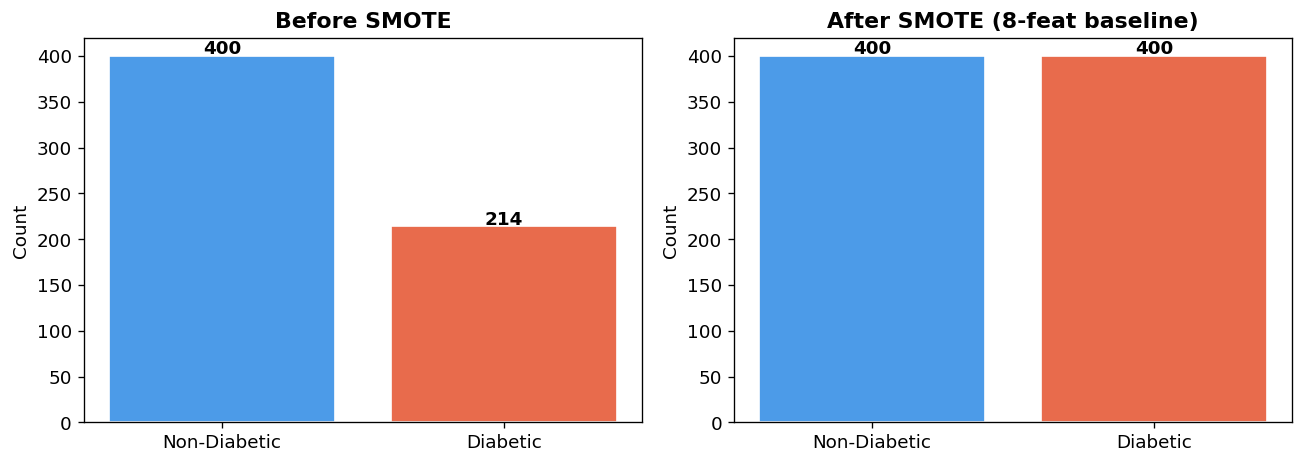

In [25]:
# ── LDA SMOTE: reduce 8→1 first, then SMOTE in 1D space ──────────
smote_lda = SMOTE(random_state=RANDOM_STATE)
X_train_lda_sm, y_train_lda = smote_lda.fit_resample(X_train_ml_lda, y_train_raw)
print(f'LDA SMOTE    → {X_train_lda_sm.shape}  '
      f'class: {dict(zip(*np.unique(y_train_lda, return_counts=True)))}')

# ── PCA SMOTE: reduce 8→4 first, then SMOTE in 4D space ──────────
smote_pca = SMOTE(random_state=RANDOM_STATE)
X_train_pca_sm, y_train_pca = smote_pca.fit_resample(X_train_ml_pca, y_train_raw)
print(f'PCA SMOTE    → {X_train_pca_sm.shape}  '
      f'class: {dict(zip(*np.unique(y_train_pca, return_counts=True)))}')

# ── 8-feat SMOTE: baseline (no reduction) ─────────────────────────
smote = SMOTE(random_state=RANDOM_STATE)
X_train_ml_sm, y_train_ml = smote.fit_resample(X_train_ml_scaled_8, y_train_raw)
print(f'8-feat SMOTE → {X_train_ml_sm.shape}  '
      f'class: {dict(zip(*np.unique(y_train_ml, return_counts=True)))}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax_s, cnts, title in [
    (axes[0], [int((y_train_raw==0).sum()), int((y_train_raw==1).sum())], 'Before SMOTE'),
    (axes[1], [int((y_train_ml==0).sum()),  int((y_train_ml==1).sum())],  'After SMOTE (8-feat baseline)'),
]:
    ax_s.bar(['Non-Diabetic', 'Diabetic'], cnts,
             color=['#4C9BE8', '#E86B4C'], edgecolor='white')
    ax_s.set_title(title, fontweight='bold')
    ax_s.set_ylabel('Count')
    for j, v in enumerate(cnts):
        ax_s.text(j, v + 2, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/plots/07_smote_balance.png', bbox_inches='tight')
plt.show()

In [26]:
np.save('../outputs/models/X_train_ml_scaled_8.npy', X_train_ml_scaled_8)
np.save('../outputs/models/X_test_ml.npy',           X_test_ml_scaled_8)
np.save('../outputs/models/y_train_raw.npy',         y_train_raw)
np.save('../outputs/models/y_test.npy',              y_test)
np.save('../outputs/models/X_train_raw.npy',         X_train_raw)
np.save('../outputs/models/X_test_raw.npy',          X_test_raw)
print("All preprocessing artifacts saved.")

All preprocessing artifacts saved.


**CLASSICAL ML MODELS + ENSEMBLE**

In [27]:
def evaluate_model(name, model, Xtr, ytr, Xte, yte):
    model.fit(Xtr, ytr)
    yp   = model.predict(Xte)
    yprb = model.predict_proba(Xte)[:,1] if hasattr(model, 'predict_proba') else None
    tn, fp, fn, tp = confusion_matrix(yte, yp).ravel()
    return {
        'Model':       name,
        'Accuracy':    round(accuracy_score(yte, yp)*100, 2),
        'Precision':   round(precision_score(yte, yp, zero_division=0)*100, 2),
        'Recall':      round(recall_score(yte, yp, zero_division=0)*100, 2),
        'Specificity': round(tn/(tn+fp)*100, 2),
        'F1':          round(f1_score(yte, yp, zero_division=0)*100, 2),
        'MCC':         round(matthews_corrcoef(yte, yp), 4),
        'ROC_AUC':     round(roc_auc_score(yte, yprb)*100, 2) if yprb is not None else 'N/A',
    }, model

In [28]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
results_list = []

lr_gs = GridSearchCV(
    ImbPipeline([('smote', SMOTE(random_state=RANDOM_STATE)),
                 ('clf',   LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]),
    {'clf__C': [0.01, 0.1, 1, 10], 'clf__solver': ['lbfgs', 'liblinear']},
    cv=cv, scoring='f1', n_jobs=-1
)
lr_gs.fit(X_train_ml_scaled_8, y_train_raw)
lr_best = lr_gs.best_estimator_
res, _ = evaluate_model('Logistic Regression', lr_best,
                         X_train_ml_scaled_8, y_train_raw, X_test_ml_scaled_8, y_test)
results_list.append(res)
print(f"LR         → {res['Accuracy']}%  params: {lr_gs.best_params_}")

svm_gs = GridSearchCV(
    ImbPipeline([('smote', SMOTE(random_state=RANDOM_STATE)),
                 ('clf',   SVC(probability=True, random_state=RANDOM_STATE))]),
    {'clf__C': [0.1, 1, 10], 'clf__kernel': ['rbf', 'linear'], 'clf__gamma': ['scale', 'auto']},
    cv=cv, scoring='f1', n_jobs=-1
)
svm_gs.fit(X_train_ml_scaled_8, y_train_raw)
svm_best = svm_gs.best_estimator_
res, _ = evaluate_model('SVM', svm_best,
                         X_train_ml_scaled_8, y_train_raw, X_test_ml_scaled_8, y_test)
results_list.append(res)
print(f"SVM        → {res['Accuracy']}%  params: {svm_gs.best_params_}")

rf_gs = GridSearchCV(
    ImbPipeline([('smote', SMOTE(random_state=RANDOM_STATE)),
                 ('clf',   RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))]),
    {'clf__n_estimators': [100, 200, 300], 'clf__max_depth': [None, 10, 20],
     'clf__min_samples_split': [2, 5]},
    cv=cv, scoring='f1', n_jobs=-1
)
rf_gs.fit(X_train_ml_scaled_8, y_train_raw)
rf_best = rf_gs.best_estimator_
res, _ = evaluate_model('Random Forest', rf_best,
                         X_train_ml_scaled_8, y_train_raw, X_test_ml_scaled_8, y_test)
results_list.append(res)
print(f"RF         → {res['Accuracy']}%  params: {rf_gs.best_params_}")

xgb_gs = GridSearchCV(
    ImbPipeline([('smote', SMOTE(random_state=RANDOM_STATE)),
                 ('clf',   XGBClassifier(use_label_encoder=False, eval_metric='logloss',
                                         random_state=RANDOM_STATE))]),
    {'clf__n_estimators': [100, 200], 'clf__max_depth': [3, 5, 7],
     'clf__learning_rate': [0.05, 0.1, 0.2], 'clf__subsample': [0.8, 1.0]},
    cv=cv, scoring='f1', n_jobs=-1
)
xgb_gs.fit(X_train_ml_scaled_8, y_train_raw)
xgb_best = xgb_gs.best_estimator_
res, _ = evaluate_model('XGBoost', xgb_best,
                         X_train_ml_scaled_8, y_train_raw, X_test_ml_scaled_8, y_test)
results_list.append(res)
print(f"XGBoost    → {res['Accuracy']}%  params: {xgb_gs.best_params_}")

for name, clf in [
    ('Extra Trees',   ExtraTreesClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
    ('Decision Tree', DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE)),
    ('Naive Bayes',   GaussianNB()),
    ('KNN',           KNeighborsClassifier(n_neighbors=7)),
]:
    pipe = ImbPipeline([('smote', SMOTE(random_state=RANDOM_STATE)), ('clf', clf)])
    res, fitted = evaluate_model(name, pipe,
                                  X_train_ml_scaled_8, y_train_raw, X_test_ml_scaled_8, y_test)
    results_list.append(res)
    print(f"{name:<15} → {res['Accuracy']}%")
    if name == 'Extra Trees':
        etc_best = fitted

LR         → 78.57%  params: {'clf__C': 1, 'clf__solver': 'liblinear'}
SVM        → 77.92%  params: {'clf__C': 1, 'clf__gamma': 'scale', 'clf__kernel': 'rbf'}
RF         → 75.97%  params: {'clf__max_depth': None, 'clf__min_samples_split': 5, 'clf__n_estimators': 100}
XGBoost    → 81.17%  params: {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 200, 'clf__subsample': 1.0}
Extra Trees     → 80.52%
Decision Tree   → 74.03%
Naive Bayes     → 77.27%
KNN             → 73.38%


In [29]:
print("\nTraining 8-feat Stacking Ensemble...")

stack = StackingClassifier(
    estimators=[
        ('lr',  lr_best),
        ('svm', svm_best),
        ('rf',  rf_best),
        ('etc', ImbPipeline([('smote', SMOTE(random_state=RANDOM_STATE)),
                              ('clf',  ExtraTreesClassifier(n_estimators=300,
                                                             random_state=RANDOM_STATE,
                                                             n_jobs=-1))])),
        ('xgb', xgb_best),
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=cv,
    n_jobs=-1
)

res_stack, stack_fitted = evaluate_model(
    'Stacking Ensemble', stack,
    X_train_ml_scaled_8, y_train_raw, X_test_ml_scaled_8, y_test
)
results_list.append(res_stack)
print(f"STACKING → Accuracy: {res_stack['Accuracy']}%  "
      f"F1: {res_stack['F1']}%  AUC: {res_stack['ROC_AUC']}%")


Training 8-feat Stacking Ensemble...
STACKING → Accuracy: 82.47%  F1: 71.58%  AUC: 88.35%



                     Accuracy  Precision  Recall  Specificity     F1     MCC  ROC_AUC
Model                                                                                
Logistic Regression     78.57      68.42   72.22         82.0  70.27  0.5359    87.44
SVM                     77.92      65.15   79.63         77.0  71.67  0.5460    86.61
Random Forest           75.97      66.04   64.81         82.0  65.42  0.4702    85.78
XGBoost                 81.17      70.49   79.63         82.0  74.78  0.6013    87.33
Extra Trees             80.52      74.00   68.52         87.0  71.15  0.5658    85.52
Decision Tree           74.03      61.67   68.52         77.0  64.91  0.4454    75.01
Naive Bayes             77.27      67.27   68.52         82.0  67.89  0.5031    85.44
KNN                     73.38      59.15   77.78         71.0  67.20  0.4669    81.35
Stacking Ensemble       82.47      82.93   62.96         93.0  71.58  0.6042    88.35

★ Best: Stacking Ensemble — 82.47%


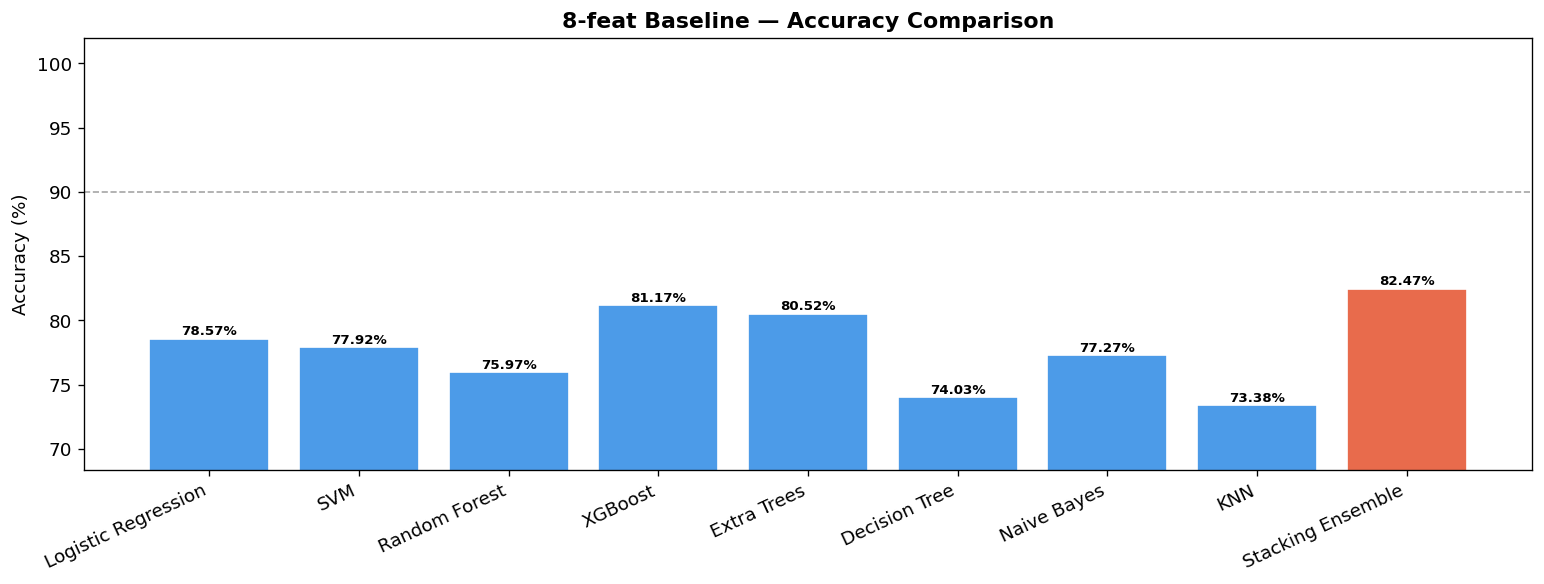

In [30]:
df_results = pd.DataFrame(results_list).set_index('Model')
print("\n" + "=" * 80)
print(df_results.to_string())
print("=" * 80)
best_name = df_results['Accuracy'].idxmax()
print(f"\n★ Best: {best_name} — {df_results.loc[best_name,'Accuracy']}%")
df_results.to_csv('../outputs/metrics/classical_ml_results.csv')

fig, ax = plt.subplots(figsize=(13, 5))
bar_colors = ['#E86B4C' if 'Ensemble' in m else '#4C9BE8' for m in df_results.index]
bars = ax.bar(df_results.index, df_results['Accuracy'], color=bar_colors, edgecolor='white')
ax.set_ylabel('Accuracy (%)')
ax.set_title('8-feat Baseline — Accuracy Comparison', fontweight='bold')
ax.set_ylim(df_results['Accuracy'].astype(float).min() - 5, 102)
ax.axhline(90, color='gray', linestyle='--', linewidth=1, alpha=0.7)
plt.xticks(rotation=25, ha='right')
for bar, val in zip(bars, df_results['Accuracy']):
    ax.text(bar.get_x()+bar.get_width()/2, float(val)+0.3, f'{val}%',
            ha='center', fontsize=8, fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/plots/10_classical_accuracy.png', bbox_inches='tight')
plt.show()

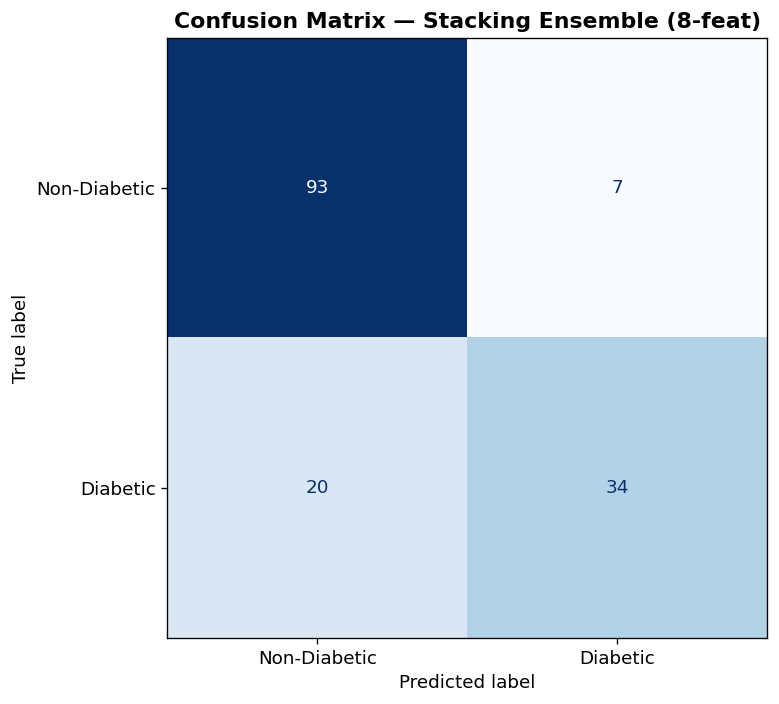

In [31]:
fig, ax = plt.subplots(figsize=(7, 6))
cm = confusion_matrix(y_test, stack_fitted.predict(X_test_ml_scaled_8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=['Non-Diabetic', 'Diabetic'])
disp.plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title('Confusion Matrix — Stacking Ensemble (8-feat)', fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/plots/11_ensemble_cm.png', bbox_inches='tight')
plt.show()

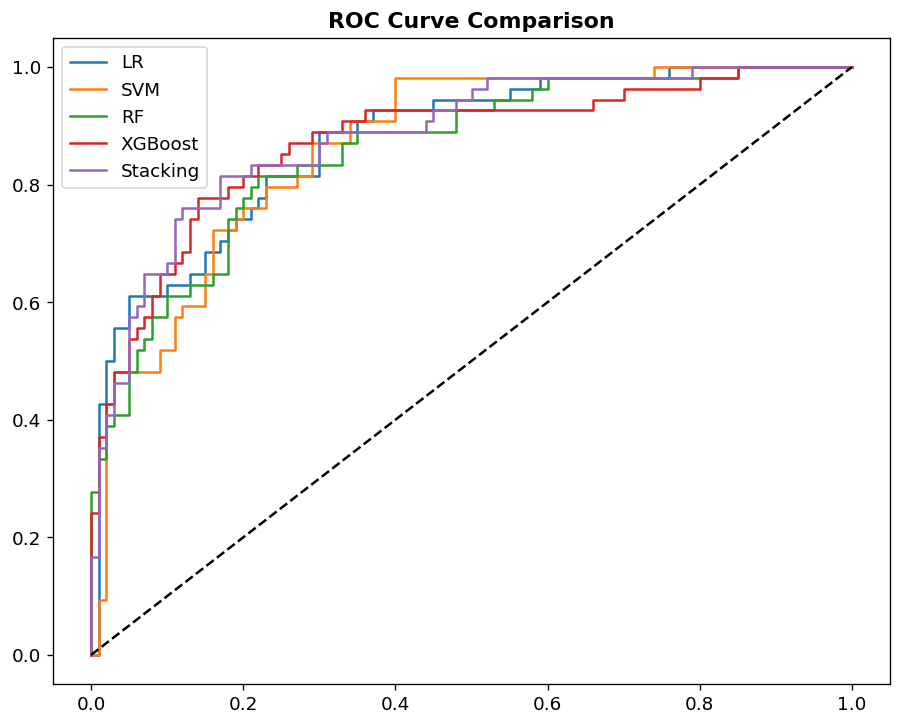

In [32]:
models = [
    ('LR', lr_best),
    ('SVM', svm_best),
    ('RF', rf_best),
    ('XGBoost', xgb_best),
    ('Stacking', stack_fitted)
]

fig, ax = plt.subplots(figsize=(9, 7))

for nm, mdl in models:
    if nm != 'Stacking':
        mdl.fit(X_train_ml_sm, y_train_ml)

    probs = mdl.predict_proba(X_test_ml_scaled_8)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    ax.plot(fpr, tpr, label=nm)

ax.plot([0,1], [0,1], 'k--')
ax.set_title('ROC Curve Comparison', fontweight='bold')
ax.legend()

plt.show()

**PCA Branch — Classical ML Models**

LR (PCA)       → 77.92%  params: {'clf__C': 0.01, 'clf__solver': 'liblinear'}
SVM (PCA)      → 75.97%  params: {'clf__C': 10, 'clf__gamma': 'auto', 'clf__kernel': 'rbf'}
RF (PCA)       → 75.32%  params: {'clf__max_depth': 10, 'clf__min_samples_split': 5, 'clf__n_estimators': 200}
XGBoost (PCA)  → 76.62%  params: {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 100, 'clf__subsample': 0.8}
Extra Trees (PCA)        → 76.62%
Decision Tree (PCA)      → 70.78%
Naive Bayes (PCA)        → 74.03%
KNN (PCA)                → 77.27%

Training PCA Stacking Ensemble...
STACKING (PCA) → Accuracy: 79.22%  F1: 65.96%  AUC: 87.07%

                     Accuracy  Precision  Recall  Specificity     F1     MCC  ROC_AUC
Model                                                                                
LR (PCA)                77.92      66.67   74.07         80.0  70.18  0.5291    85.57
SVM (PCA)               75.97      61.04   87.04         70.0  71.76  0.5443    87.37
Random Fores

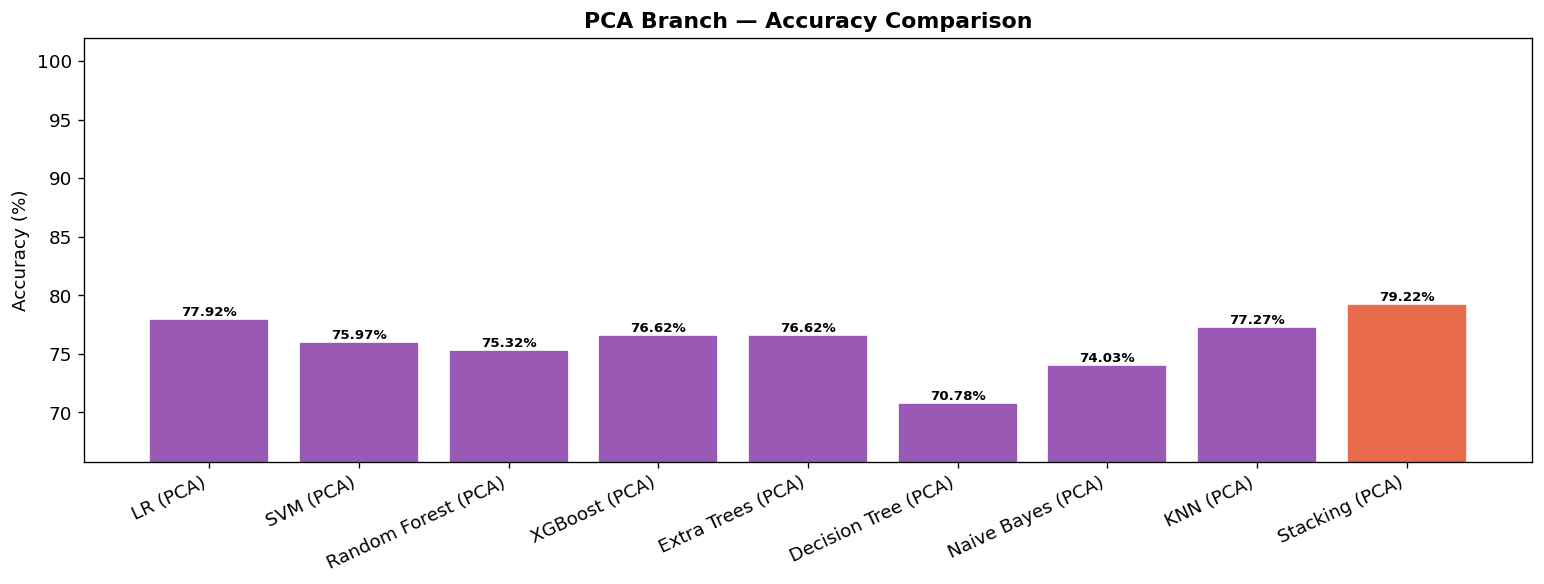

In [33]:
# ══════════════════════════════════════════════════════════════════
#  PCA BRANCH — 8 → 4 principal components
#  Train: X_train_ml_pca (614,4) / y_train_raw   [SMOTE inside CV]
#  Test : X_test_ml_pca  (154,4) / y_test
# ══════════════════════════════════════════════════════════════════
pca_results_list = []
pca_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

lr_pca_gs = GridSearchCV(
    ImbPipeline([('smote', SMOTE(random_state=RANDOM_STATE)),
                 ('clf',   LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]),
    {'clf__C': [0.01, 0.1, 1, 10], 'clf__solver': ['lbfgs', 'liblinear']},
    cv=pca_cv, scoring='f1', n_jobs=-1
)
lr_pca_gs.fit(X_train_ml_pca, y_train_raw)
lr_pca_best = lr_pca_gs.best_estimator_
res, _ = evaluate_model('LR (PCA)', lr_pca_best,
                         X_train_ml_pca, y_train_raw, X_test_ml_pca, y_test)
pca_results_list.append(res)
print(f"LR (PCA)       → {res['Accuracy']}%  params: {lr_pca_gs.best_params_}")

svm_pca_gs = GridSearchCV(
    ImbPipeline([('smote', SMOTE(random_state=RANDOM_STATE)),
                 ('clf',   SVC(probability=True, random_state=RANDOM_STATE))]),
    {'clf__C': [0.1, 1, 10], 'clf__kernel': ['rbf', 'linear'], 'clf__gamma': ['scale', 'auto']},
    cv=pca_cv, scoring='f1', n_jobs=-1
)
svm_pca_gs.fit(X_train_ml_pca, y_train_raw)
svm_pca_best = svm_pca_gs.best_estimator_
res, _ = evaluate_model('SVM (PCA)', svm_pca_best,
                         X_train_ml_pca, y_train_raw, X_test_ml_pca, y_test)
pca_results_list.append(res)
print(f"SVM (PCA)      → {res['Accuracy']}%  params: {svm_pca_gs.best_params_}")

rf_pca_gs = GridSearchCV(
    ImbPipeline([('smote', SMOTE(random_state=RANDOM_STATE)),
                 ('clf',   RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))]),
    {'clf__n_estimators': [100, 200, 300], 'clf__max_depth': [None, 10, 20],
     'clf__min_samples_split': [2, 5]},
    cv=pca_cv, scoring='f1', n_jobs=-1
)
rf_pca_gs.fit(X_train_ml_pca, y_train_raw)
rf_pca_best = rf_pca_gs.best_estimator_
res, _ = evaluate_model('Random Forest (PCA)', rf_pca_best,
                         X_train_ml_pca, y_train_raw, X_test_ml_pca, y_test)
pca_results_list.append(res)
print(f"RF (PCA)       → {res['Accuracy']}%  params: {rf_pca_gs.best_params_}")

xgb_pca_gs = GridSearchCV(
    ImbPipeline([('smote', SMOTE(random_state=RANDOM_STATE)),
                 ('clf',   XGBClassifier(use_label_encoder=False, eval_metric='logloss',
                                         random_state=RANDOM_STATE))]),
    {'clf__n_estimators': [100, 200], 'clf__max_depth': [3, 5, 7],
     'clf__learning_rate': [0.05, 0.1, 0.2], 'clf__subsample': [0.8, 1.0]},
    cv=pca_cv, scoring='f1', n_jobs=-1
)
xgb_pca_gs.fit(X_train_ml_pca, y_train_raw)
xgb_pca_best = xgb_pca_gs.best_estimator_
res, _ = evaluate_model('XGBoost (PCA)', xgb_pca_best,
                         X_train_ml_pca, y_train_raw, X_test_ml_pca, y_test)
pca_results_list.append(res)
print(f"XGBoost (PCA)  → {res['Accuracy']}%  params: {xgb_pca_gs.best_params_}")

for name, clf in [
    ('Extra Trees (PCA)',   ExtraTreesClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
    ('Decision Tree (PCA)', DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE)),
    ('Naive Bayes (PCA)',   GaussianNB()),
    ('KNN (PCA)',           KNeighborsClassifier(n_neighbors=7)),
]:
    pipe = ImbPipeline([('smote', SMOTE(random_state=RANDOM_STATE)), ('clf', clf)])
    res, fitted = evaluate_model(name, pipe,
                                  X_train_ml_pca, y_train_raw, X_test_ml_pca, y_test)
    pca_results_list.append(res)
    print(f"{name:<24} → {res['Accuracy']}%")
    if name == 'Extra Trees (PCA)':
        etc_pca_best = fitted

print("\nTraining PCA Stacking Ensemble...")
pca_stack = StackingClassifier(
    estimators=[
        ('lr',  lr_pca_best),
        ('svm', svm_pca_best),
        ('rf',  rf_pca_best),
        ('etc', ImbPipeline([('smote', SMOTE(random_state=RANDOM_STATE)),
                              ('clf',  ExtraTreesClassifier(n_estimators=300,
                                                             random_state=RANDOM_STATE,
                                                             n_jobs=-1))])),
        ('xgb', xgb_pca_best),
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=pca_cv,
    n_jobs=-1
)
res_pca_stack, pca_stack_fitted = evaluate_model(
    'Stacking (PCA)', pca_stack,
    X_train_ml_pca, y_train_raw, X_test_ml_pca, y_test
)
pca_results_list.append(res_pca_stack)
print(f"STACKING (PCA) → Accuracy: {res_pca_stack['Accuracy']}%  "
      f"F1: {res_pca_stack['F1']}%  AUC: {res_pca_stack['ROC_AUC']}%")

df_pca_results = pd.DataFrame(pca_results_list).set_index('Model')
print("\n" + "=" * 80)
print(df_pca_results.to_string())
print("=" * 80)
best_pca_name = df_pca_results['Accuracy'].idxmax()
print(f"\n★ Best (PCA): {best_pca_name} — {df_pca_results.loc[best_pca_name,'Accuracy']}%")
df_pca_results.to_csv('../outputs/metrics/pca_branch_results.csv')

fig, ax = plt.subplots(figsize=(13, 5))
bar_colors_pca = ['#E86B4C' if 'Stacking' in m else '#9B59B6' for m in df_pca_results.index]
bars = ax.bar(df_pca_results.index, df_pca_results['Accuracy'],
              color=bar_colors_pca, edgecolor='white')
ax.set_ylabel('Accuracy (%)')
ax.set_title('PCA Branch — Accuracy Comparison', fontweight='bold')
ax.set_ylim(df_pca_results['Accuracy'].astype(float).min() - 5, 102)
plt.xticks(rotation=25, ha='right')
for bar, val in zip(bars, df_pca_results['Accuracy']):
    ax.text(bar.get_x()+bar.get_width()/2, float(val)+0.3, f'{val}%',
            ha='center', fontsize=8, fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/plots/pca_branch_accuracy.png', bbox_inches='tight')
plt.show()

**LDA Branch — Classical ML Models**

LR (LDA)       → 78.57%  params: {'clf__C': 0.01, 'clf__solver': 'liblinear'}
SVM (LDA)      → 78.57%  params: {'clf__C': 0.1, 'clf__gamma': 'scale', 'clf__kernel': 'linear'}
RF (LDA)       → 77.27%  params: {'clf__max_depth': 10, 'clf__min_samples_split': 5, 'clf__n_estimators': 200}
XGBoost (LDA)  → 75.97%  params: {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 100, 'clf__subsample': 0.8}
Extra Trees (LDA)        → 68.83%
Decision Tree (LDA)      → 73.38%
Naive Bayes (LDA)        → 79.87%
KNN (LDA)                → 77.92%

Training LDA Stacking Ensemble...
STACKING (LDA) → Accuracy: 81.82%  F1: 68.89%  AUC: 86.41%

                     Accuracy  Precision  Recall  Specificity     F1     MCC  ROC_AUC
Model                                                                                
LR (LDA)                78.57      67.80   74.07         81.0  70.80  0.5406    87.31
SVM (LDA)               78.57      69.09   70.37         83.0  69.72  0.5315    87.31
Random 

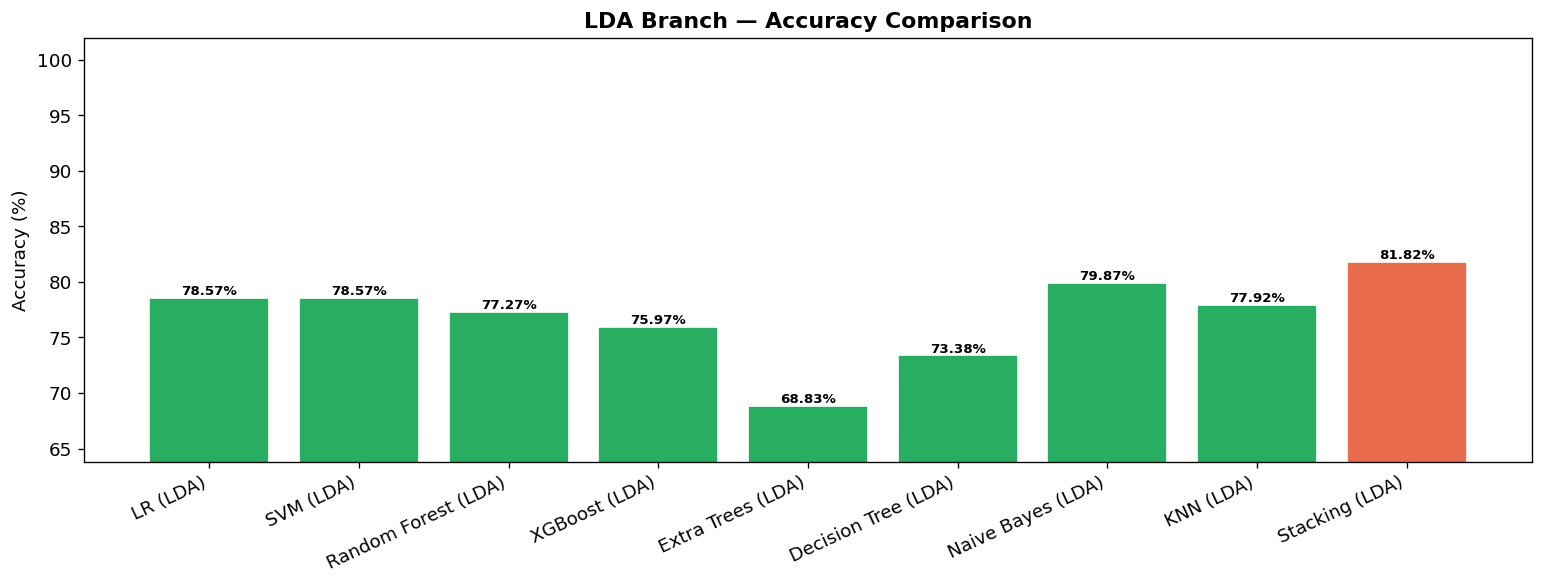

In [34]:
# ══════════════════════════════════════════════════════════════════
#  LDA BRANCH — 8 → 1 discriminant component
#  Train: X_train_ml_lda (614,1) / y_train_raw   [SMOTE inside CV]
#  Test : X_test_ml_lda  (154,1) / y_test
# ══════════════════════════════════════════════════════════════════
lda_results_list = []
lda_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

lr_lda_gs = GridSearchCV(
    ImbPipeline([('smote', SMOTE(random_state=RANDOM_STATE)),
                 ('clf',   LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]),
    {'clf__C': [0.01, 0.1, 1, 10], 'clf__solver': ['lbfgs', 'liblinear']},
    cv=lda_cv, scoring='f1', n_jobs=-1
)
lr_lda_gs.fit(X_train_ml_lda, y_train_raw)
lr_lda_best = lr_lda_gs.best_estimator_
res, _ = evaluate_model('LR (LDA)', lr_lda_best,
                         X_train_ml_lda, y_train_raw, X_test_ml_lda, y_test)
lda_results_list.append(res)
print(f"LR (LDA)       → {res['Accuracy']}%  params: {lr_lda_gs.best_params_}")

svm_lda_gs = GridSearchCV(
    ImbPipeline([('smote', SMOTE(random_state=RANDOM_STATE)),
                 ('clf',   SVC(probability=True, random_state=RANDOM_STATE))]),
    {'clf__C': [0.1, 1, 10], 'clf__kernel': ['rbf', 'linear'], 'clf__gamma': ['scale', 'auto']},
    cv=lda_cv, scoring='f1', n_jobs=-1
)
svm_lda_gs.fit(X_train_ml_lda, y_train_raw)
svm_lda_best = svm_lda_gs.best_estimator_
res, _ = evaluate_model('SVM (LDA)', svm_lda_best,
                         X_train_ml_lda, y_train_raw, X_test_ml_lda, y_test)
lda_results_list.append(res)
print(f"SVM (LDA)      → {res['Accuracy']}%  params: {svm_lda_gs.best_params_}")

rf_lda_gs = GridSearchCV(
    ImbPipeline([('smote', SMOTE(random_state=RANDOM_STATE)),
                 ('clf',   RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))]),
    {'clf__n_estimators': [100, 200, 300], 'clf__max_depth': [None, 10, 20],
     'clf__min_samples_split': [2, 5]},
    cv=lda_cv, scoring='f1', n_jobs=-1
)
rf_lda_gs.fit(X_train_ml_lda, y_train_raw)
rf_lda_best = rf_lda_gs.best_estimator_
res, _ = evaluate_model('Random Forest (LDA)', rf_lda_best,
                         X_train_ml_lda, y_train_raw, X_test_ml_lda, y_test)
lda_results_list.append(res)
print(f"RF (LDA)       → {res['Accuracy']}%  params: {rf_lda_gs.best_params_}")

xgb_lda_gs = GridSearchCV(
    ImbPipeline([('smote', SMOTE(random_state=RANDOM_STATE)),
                 ('clf',   XGBClassifier(use_label_encoder=False, eval_metric='logloss',
                                         random_state=RANDOM_STATE))]),
    {'clf__n_estimators': [100, 200], 'clf__max_depth': [3, 5, 7],
     'clf__learning_rate': [0.05, 0.1, 0.2], 'clf__subsample': [0.8, 1.0]},
    cv=lda_cv, scoring='f1', n_jobs=-1
)
xgb_lda_gs.fit(X_train_ml_lda, y_train_raw)
xgb_lda_best = xgb_lda_gs.best_estimator_
res, _ = evaluate_model('XGBoost (LDA)', xgb_lda_best,
                         X_train_ml_lda, y_train_raw, X_test_ml_lda, y_test)
lda_results_list.append(res)
print(f"XGBoost (LDA)  → {res['Accuracy']}%  params: {xgb_lda_gs.best_params_}")

for name, clf in [
    ('Extra Trees (LDA)',   ExtraTreesClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
    ('Decision Tree (LDA)', DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE)),
    ('Naive Bayes (LDA)',   GaussianNB()),
    ('KNN (LDA)',           KNeighborsClassifier(n_neighbors=7)),
]:
    pipe = ImbPipeline([('smote', SMOTE(random_state=RANDOM_STATE)), ('clf', clf)])
    res, fitted = evaluate_model(name, pipe,
                                  X_train_ml_lda, y_train_raw, X_test_ml_lda, y_test)
    lda_results_list.append(res)
    print(f"{name:<24} → {res['Accuracy']}%")
    if name == 'Extra Trees (LDA)':
        etc_lda_best = fitted

print("\nTraining LDA Stacking Ensemble...")
lda_stack = StackingClassifier(
    estimators=[
        ('lr',  lr_lda_best),
        ('svm', svm_lda_best),
        ('rf',  rf_lda_best),
        ('etc', ImbPipeline([('smote', SMOTE(random_state=RANDOM_STATE)),
                              ('clf',  ExtraTreesClassifier(n_estimators=300,
                                                             random_state=RANDOM_STATE,
                                                             n_jobs=-1))])),
        ('xgb', xgb_lda_best),
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=lda_cv,
    n_jobs=-1
)
res_lda_stack, lda_stack_fitted = evaluate_model(
    'Stacking (LDA)', lda_stack,
    X_train_ml_lda, y_train_raw, X_test_ml_lda, y_test
)
lda_results_list.append(res_lda_stack)
print(f"STACKING (LDA) → Accuracy: {res_lda_stack['Accuracy']}%  "
      f"F1: {res_lda_stack['F1']}%  AUC: {res_lda_stack['ROC_AUC']}%")

df_lda_results = pd.DataFrame(lda_results_list).set_index('Model')
print("\n" + "=" * 80)
print(df_lda_results.to_string())
print("=" * 80)
best_lda_name = df_lda_results['Accuracy'].idxmax()
print(f"\n★ Best (LDA): {best_lda_name} — {df_lda_results.loc[best_lda_name,'Accuracy']}%")
df_lda_results.to_csv('../outputs/metrics/lda_branch_results.csv')

fig, ax = plt.subplots(figsize=(13, 5))
bar_colors_lda = ['#E86B4C' if 'Stacking' in m else '#27AE60' for m in df_lda_results.index]
bars = ax.bar(df_lda_results.index, df_lda_results['Accuracy'],
              color=bar_colors_lda, edgecolor='white')
ax.set_ylabel('Accuracy (%)')
ax.set_title('LDA Branch — Accuracy Comparison', fontweight='bold')
ax.set_ylim(df_lda_results['Accuracy'].astype(float).min() - 5, 102)
plt.xticks(rotation=25, ha='right')
for bar, val in zip(bars, df_lda_results['Accuracy']):
    ax.text(bar.get_x()+bar.get_width()/2, float(val)+0.3, f'{val}%',
            ha='center', fontsize=8, fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/plots/lda_branch_accuracy.png', bbox_inches='tight')
plt.show()

**Branch Comparison — 8-feat vs PCA vs LDA**

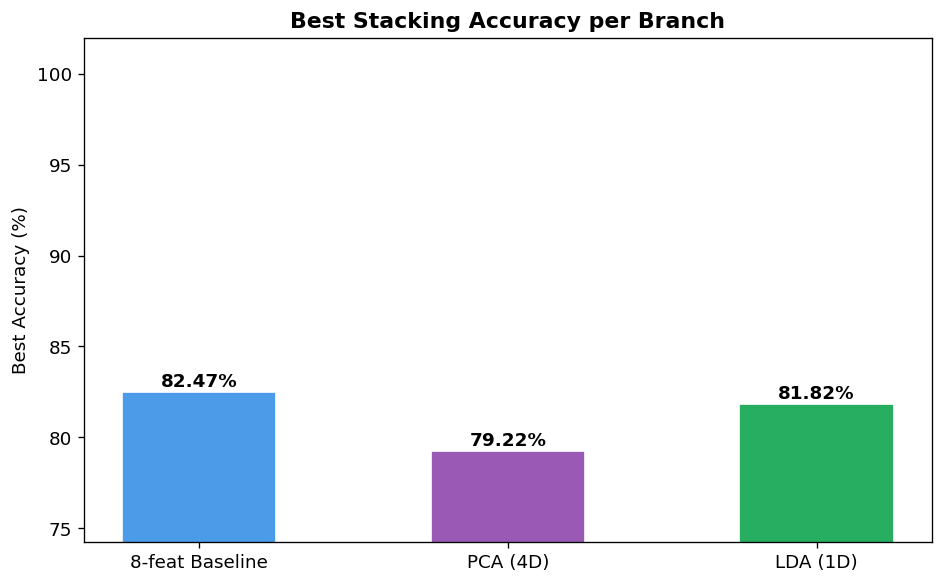

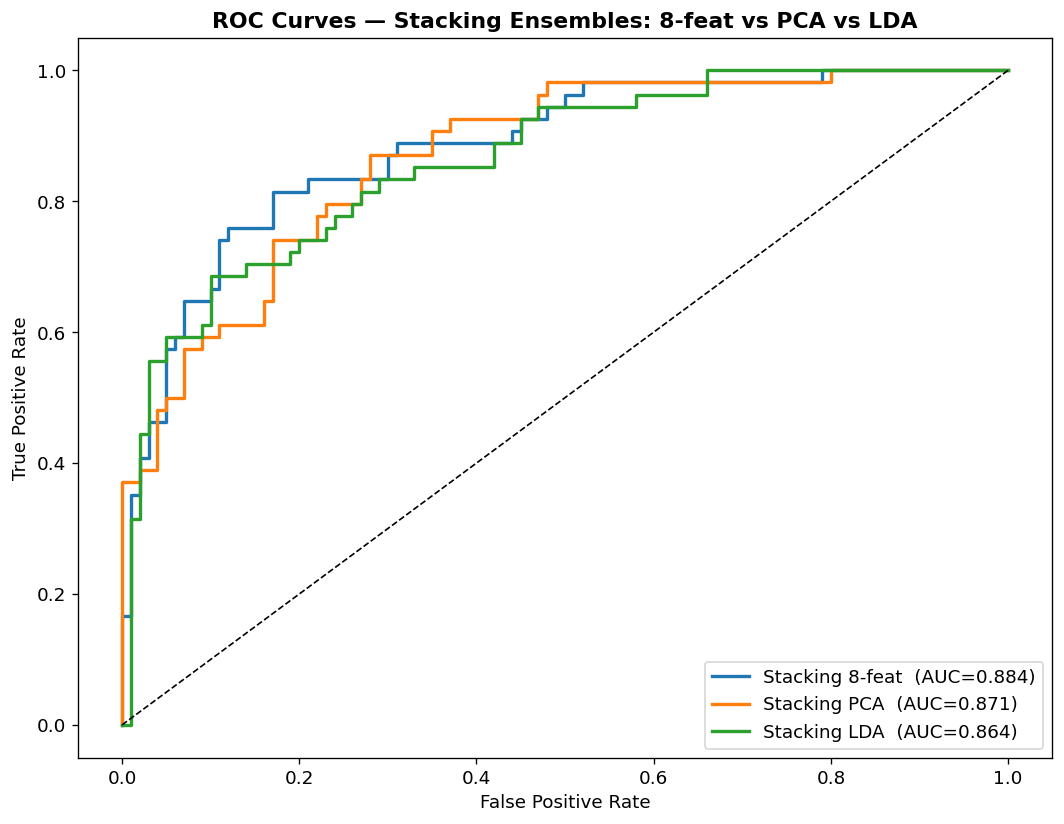


BRANCH SUMMARY — Best model per branch
  8-feat     | Stacking Ensemble         | Acc: 82.47%  F1: 71.58%  AUC: 88.35%
  PCA        | Stacking (PCA)            | Acc: 79.22%  F1: 65.96%  AUC: 87.07%
  LDA        | Stacking (LDA)            | Acc: 81.82%  F1: 68.89%  AUC: 86.41%

All branch results → ../outputs/metrics/all_branches_comparison.csv


In [35]:
# ── Tag each branch ───────────────────────────────────────────────
df_results_tagged     = df_results.copy();     df_results_tagged['Branch']     = '8-feat'
df_pca_results_tagged = df_pca_results.copy(); df_pca_results_tagged['Branch'] = 'PCA (4D)'
df_lda_results_tagged = df_lda_results.copy(); df_lda_results_tagged['Branch'] = 'LDA (1D)'

df_all = pd.concat([df_results_tagged, df_pca_results_tagged, df_lda_results_tagged])
df_all.to_csv('../outputs/metrics/all_branches_comparison.csv')

# ── Best accuracy per branch bar chart ────────────────────────────
best_8feat_acc = float(df_results['Accuracy'].max())
best_pca_acc   = float(df_pca_results['Accuracy'].max())
best_lda_acc   = float(df_lda_results['Accuracy'].max())

branch_names  = ['8-feat Baseline', 'PCA (4D)', 'LDA (1D)']
branch_accs   = [best_8feat_acc, best_pca_acc, best_lda_acc]
branch_colors = ['#4C9BE8', '#9B59B6', '#27AE60']

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(branch_names, branch_accs, color=branch_colors, edgecolor='white', width=0.5)
ax.set_ylabel('Best Accuracy (%)')
ax.set_title('Best Stacking Accuracy per Branch', fontweight='bold')
ax.set_ylim(min(branch_accs) - 5, 102)
for bar, val in zip(bars, branch_accs):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.3, f'{val}%',
            ha='center', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/plots/branch_comparison_accuracy.png', bbox_inches='tight')
plt.show()

# ── ROC curves — stacking ensembles across all three branches ─────
fig, ax = plt.subplots(figsize=(9, 7))
for nm, mdl, Xte in [
    ('Stacking 8-feat', stack_fitted,     X_test_ml_scaled_8),
    ('Stacking PCA',    pca_stack_fitted, X_test_ml_pca),
    ('Stacking LDA',    lda_stack_fitted, X_test_ml_lda),
]:
    probs = mdl.predict_proba(Xte)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc_val = sk_auc(fpr, tpr)
    ax.plot(fpr, tpr, linewidth=2, label=f'{nm}  (AUC={auc_val:.3f})')
ax.plot([0,1], [0,1], 'k--', linewidth=1)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves — Stacking Ensembles: 8-feat vs PCA vs LDA', fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('../outputs/plots/branch_comparison_roc.png', bbox_inches='tight')
plt.show()

# ── Summary table ─────────────────────────────────────────────────
print("\n" + "=" * 80)
print("BRANCH SUMMARY — Best model per branch")
print("=" * 80)
for branch_label, df_b in [('8-feat', df_results), ('PCA', df_pca_results), ('LDA', df_lda_results)]:
    best_n = df_b['Accuracy'].idxmax()
    r = df_b.loc[best_n]
    print(f"  {branch_label:<10} | {best_n:<25} | Acc: {r['Accuracy']}%  "
          f"F1: {r['F1']}%  AUC: {r['ROC_AUC']}%")
print("=" * 80)
print("\nAll branch results → ../outputs/metrics/all_branches_comparison.csv")

In [36]:
import os, joblib, numpy as np, pandas as pd
os.makedirs('../outputs/hybrid', exist_ok=True)
y_proba_xgb = xgb_best.predict_proba(X_test_ml_scaled_8)[:, 1]
y_pred_xgb  = xgb_best.predict(X_test_ml_scaled_8)
pd.DataFrame({'sample_id': np.arange(len(y_test)), 'y_true': y_test,
              'xgb_proba': y_proba_xgb, 'xgb_pred': y_pred_xgb,
}).to_csv('../outputs/hybrid/classical_test_outputs.csv', index=False)
joblib.dump(xgb_best, '../outputs/hybrid/xgb_model.pkl')
pd.DataFrame(X_test_ml_scaled_8, columns=FEATURE_COLS).to_csv(
    '../outputs/hybrid/X_test_classical.csv', index=False)